# 07 · MalSkills — 1,000-skill scan analysis

**Purpose.** Analyze the existing `results/malskills/package_test_2` scan output using MalSkills' own verdicts, security-sensitive operations (SSOs), behavior patterns, formal rules, and proof records. The notebook loads saved results only: it **does not rescan or execute** skill content.

**Central question:** Why were only **4 of 1,000** scanned skills assigned malicious verdicts? We break down the scan outcomes, identify the patterns/rules linked to those verdicts, trace evidence for each flagged skill, and compare operation counts against unflagged skills.

**Starting point to verify using local data:** `skill_0050`, `skill_0452`, `skill_0636`, and `skill_0964` appear with `Malware_Delivery` and `Remote_Code_Execution` pattern matches. The notebook derives findings from saved reports rather than treating these names or classifications as hard-coded results.

**Terminology:** A *MalSkills malicious verdict* is a scanner output. An SSO is an operation detected by the scanner; finding an SSO alone does not imply a malicious verdict.


## 0. Setup

Run inside the local `SkillGuard` repository with `results/malskills/package_test_2/scan_results.jsonl` and its `cases/` subfolders available. This notebook is **read-only with respect to the source scan files**; charts, CSVs, and the report go into `results/malskills_analysis/package_test_2/`.

Requires `pandas`, `numpy`, `matplotlib`, and `IPython`. Override `MALSKILLS_RUN_DIR` if the saved scan is elsewhere.


In [1]:
from pathlib import Path
import os, json, re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

EXPECTED_SKILLS = 1000
DETAIL_MODE = "all"  # "all": all preserved cases; "selected": flagged + high-SSO benigns
HIGH_SSO_BENIGN_N = 25
RANDOM_SEED = 2027
SHOW_MATCHED_TEXT = True           # print untrusted snippets as inert text only
EXPORT_MATCHED_TEXT = False        # default: do not export untrusted snippets into tracked CSVs
SAVE_OUTPUTS = True

HERE = Path.cwd().resolve()
def locate_repo(start):
    for p in [start, *start.parents]:
        if (p / "results" / "malskills" / "package_test_2" / "scan_results.jsonl").exists():
            return p
    return start.parent if start.name == 'notebooks' else start

REPO_ROOT = locate_repo(HERE)
RUN_DIR = Path(os.environ.get('MALSKILLS_RUN_DIR', REPO_ROOT / 'results' / 'malskills' / 'package_test_2')).expanduser().resolve()
OUT_DIR = Path(os.environ.get('MALSKILLS_OUT_DIR', REPO_ROOT / 'results' / 'malskills_analysis' / 'package_test_2')).expanduser().resolve()
FIG_DIR, TABLE_DIR = OUT_DIR / 'figures', OUT_DIR / 'tables'
if SAVE_OUTPUTS:
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    TABLE_DIR.mkdir(parents=True, exist_ok=True)
print('Input:', RUN_DIR)
print('Output:', OUT_DIR)
if not (RUN_DIR / 'scan_results.jsonl').is_file():
    raise FileNotFoundError(f'Missing {RUN_DIR / "scan_results.jsonl"}. Fetch origin/rio and restore results/malskills/package_test_2, or set MALSKILLS_RUN_DIR.')


Input: /Users/samantharies/PycharmProjects/MSR2027/SkillGuard/results/malskills/package_test_2
Output: /Users/samantharies/PycharmProjects/MSR2027/SkillGuard/results/malskills_analysis/package_test_2


## 1. Corpus integrity and scan coverage

Check the denominator before calculating any percentages: total scan records, unique skill IDs, run statuses, missing or unreadable results, and locally preserved case reports. Duplicate scan rows or failed scans should not be silently treated as benign skills.


In [2]:
entries, parse_errors = [], []
with (RUN_DIR / 'scan_results.jsonl').open(encoding='utf-8') as f:
    for line_no, line in enumerate(f, start=1):
        if not line.strip():
            continue
        try:
            x = json.loads(line)
            if not isinstance(x, dict):
                raise ValueError('not a JSON object')
            entries.append(x)
        except (ValueError, json.JSONDecodeError) as exc:
            parse_errors.append({'line': line_no, 'error': str(exc)})
df = pd.DataFrame(entries)
if df.empty:
    raise ValueError('No scan results could be loaded.')
required = ['entry_id','package','status','verdict','finding_count','sso_count','pattern_matches','artifact_count','retained_output']
for c in required:
    if c not in df.columns:
        df[c] = np.nan
for c in ['finding_count','sso_count','pattern_matches','artifact_count','runtime_sec','operand_count','operand_resolution_count','observed_candidate_count','proposed_rule_count']:
    if c not in df.columns: df[c] = np.nan
    df[c] = pd.to_numeric(df[c], errors='coerce')
df['verdict'] = df['verdict'].fillna('missing').astype(str).str.lower()
df['status'] = df['status'].fillna('missing').astype(str).str.lower()
df['has_sso'] = df['sso_count'].gt(0)
df['has_pattern'] = df['pattern_matches'].gt(0)
df['is_malicious'] = df['verdict'].eq('malicious')
df['has_error'] = ~df['status'].eq('ok') | df['error'].fillna('').astype(str).str.len().gt(0) if 'error' in df else ~df['status'].eq('ok')
if 'skill_content_sha256' not in df: df['skill_content_sha256'] = np.nan
if 'patterns' not in df: df['patterns'] = [[] for _ in range(len(df))]
df['patterns'] = df['patterns'].apply(lambda a: a if isinstance(a, list) else [])

# Never follow source-provided file paths outside the selected run directory.
def case_dir(row):
    rel = row.get('retained_output')
    if not isinstance(rel, str) or not rel.strip(): return None
    candidate = (RUN_DIR / rel).resolve()
    return candidate if candidate.is_relative_to(RUN_DIR) else None

df['case_dir'] = df.apply(case_dir, axis=1)
df['case_available'] = df['case_dir'].apply(lambda p: p is not None and p.is_dir())

audit = pd.Series({
    'scan rows': len(df), 'unique entry IDs': df.entry_id.nunique(),
    'duplicate entry IDs': int(df.entry_id.duplicated().sum()),
    'unique content SHA-256': df.skill_content_sha256.nunique(dropna=True),
    'parse errors': len(parse_errors), 'non-ok scan rows': int(df.has_error.sum()),
    'retained case directories': int(df.case_available.sum()),
    'missing case directories': int((~df.case_available).sum())
}, name='value')
display(audit.to_frame())
print('Statuses:'); display(df.status.value_counts(dropna=False).rename_axis('status').to_frame('skills'))
if len(df) != EXPECTED_SKILLS: print(f'NOTE: Found {len(df):,}, expected {EXPECTED_SKILLS:,} scan rows.')
if df.entry_id.duplicated().any(): print('WARNING: Duplicate entry IDs detected; verdict rates use scan rows, not deduplicated identities.')
if parse_errors: display(pd.DataFrame(parse_errors).head())


,value
scan rows,1000
unique entry IDs,1000
duplicate entry IDs,0
unique content SHA-256,1000
parse errors,0
non-ok scan rows,0
retained case directories,1000
missing case directories,0


Statuses:


,skills
status,
ok,1000


## 2. Verdict distribution and detection funnel

The stages are distinct: **scan completed → SSO found → behavior-pattern match → malicious verdict**. A detected SSO (e.g., a command or network action) is not the same thing as a rule proving a malicious flow. The plots help locate where most skills were filtered out.


,scans,pct_all_scans
verdict,,
benign,996,99.6
malicious,4,0.4


,stage,skills,pct_all_scans
0,Scans recorded,1000,100.0
1,Scans with status = ok,1000,100.0
2,At least one SSO,271,27.1
3,At least one behavior pattern,4,0.4
4,Verdict = malicious,4,0.4


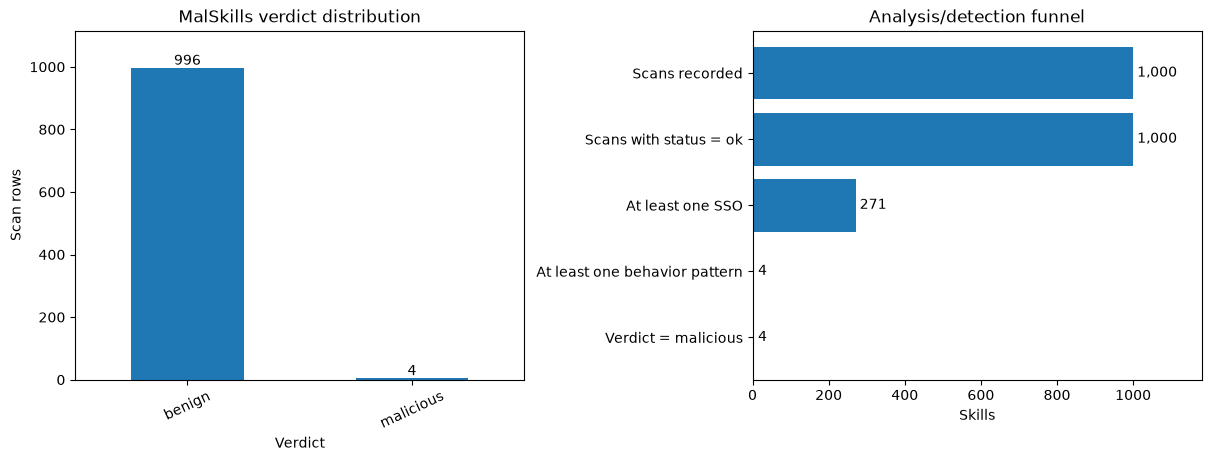

INTERPRETATION: a finding/SSO represents an observed operation, not a confirmed security defect.
Observed malicious flag rate = 0.40% (4/1,000 scan rows).


In [3]:
n = len(df)
labels = df['verdict'].value_counts().rename_axis('verdict').to_frame('scans')
labels['pct_all_scans'] = (100 * labels['scans'] / n).round(3)
display(labels)

funnel = pd.DataFrame([
    ('Scans recorded', n),
    ('Scans with status = ok', int(df.status.eq('ok').sum())),
    ('At least one SSO', int(df.has_sso.sum())),
    ('At least one behavior pattern', int(df.has_pattern.sum())),
    ('Verdict = malicious', int(df.is_malicious.sum()))
], columns=['stage','skills'])
funnel['pct_all_scans'] = (100 * funnel.skills / n).round(2)
display(funnel)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
labels.scans.plot.bar(ax=axs[0], rot=25)
axs[0].set(title='MalSkills verdict distribution', ylabel='Scan rows', xlabel='Verdict')
for i, v in enumerate(labels.scans): axs[0].text(i, v, f'{v:,}', ha='center', va='bottom')
axs[0].set_ylim(0, max(labels.scans)*1.12)
axs[1].barh(funnel.stage[::-1], funnel.skills[::-1])
axs[1].set(title='Analysis/detection funnel', xlabel='Skills')
for i, v in enumerate(funnel.skills[::-1]): axs[1].text(v, i, f' {v:,}', va='center')
axs[1].set_xlim(0, n*1.18)
if SAVE_OUTPUTS: fig.savefig(FIG_DIR / '01_verdict_and_funnel.png', dpi=180, bbox_inches='tight')
plt.show()

print('INTERPRETATION: a finding/SSO represents an observed operation, not a confirmed security defect.')
print(f'Observed malicious flag rate = {df.is_malicious.mean():.2%} ({df.is_malicious.sum():,}/{n:,} scan rows).')

## 3. Why did the remaining skills not receive a malicious verdict?

Group skills by their **furthest observed detection stage**: failed/partial scan, malicious verdict, pattern matched but no malicious verdict, SSOs without a behavior-pattern match, and no SSO. This is a classification of the **scanner's output**, not an assertion that the unflagged skills are safe.


,skills,pct
explanation_group,,
no SSO found,729,72.9
"SSO(s), no behavior pattern",267,26.7
malicious pattern / verdict,4,0.4


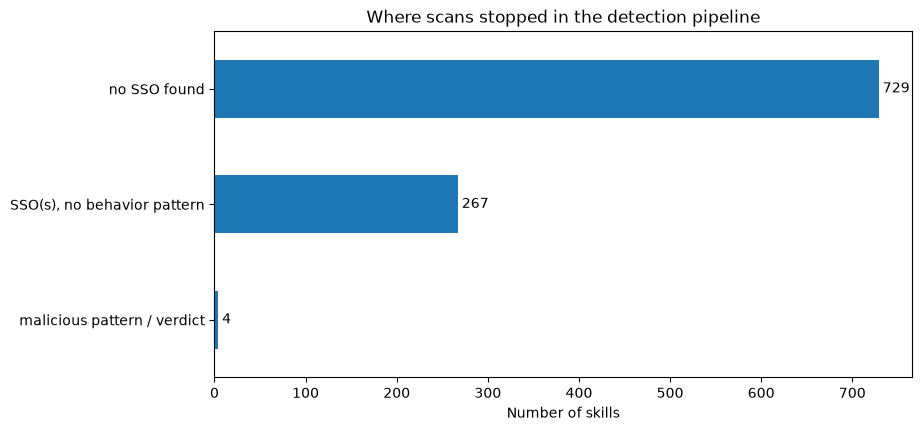

In [4]:
def funnel_reason(r):
    if bool(r['has_error']): return 'scan error / non-ok status'
    if r['is_malicious']: return 'malicious pattern / verdict'
    if r['has_pattern']: return 'pattern(s), non-malicious verdict (investigate)'
    if r['has_sso']: return 'SSO(s), no behavior pattern'
    return 'no SSO found'
df['outcome_group'] = df.apply(funnel_reason, axis=1)
reason_table = df.outcome_group.value_counts().rename_axis('explanation_group').to_frame('skills')
reason_table['pct'] = (reason_table.skills / n * 100).round(1)
display(reason_table)

fig, ax = plt.subplots(figsize=(9, 4.5))
reason_table.sort_values('skills').skills.plot.barh(ax=ax)
ax.set(title='Where scans stopped in the detection pipeline', xlabel='Number of skills', ylabel='')
for i, v in enumerate(reason_table.sort_values('skills').skills): ax.text(v, i, f' {v:,}', va='center')
if SAVE_OUTPUTS: fig.savefig(FIG_DIR / '02_outcome_groups.png', dpi=180, bbox_inches='tight')
plt.show()

## 4. Are malicious verdicts related to finding volume or folder complexity?

Compare SSO counts, number of analyzed artifacts, and other summary statistics for flagged and unflagged skills. **More SSOs does not necessarily mean malicious:** a benign result with dozens of SSOs is a useful counterexample to an interpretation based only on volume.


finding_count                   sso_count                    \
                  count   mean median max     count   mean median max   
verdict                                                                 
benign              996   2.49    0.0  84       996   2.49    0.0  84   
malicious             4  19.50   18.5  31         4  19.50   18.5  31   

          artifact_count         ... operand_count      \
                   count   mean  ...        median max   
verdict                          ...                     
benign               996   5.45  ...           0.0  81   
malicious              4  19.75  ...          18.5  31   

          operand_resolution_count                 runtime_sec                \
                             count mean median max       count   mean median   
verdict                                                                        
benign                         996  0.0    0.0   0         996  42.24  32.57   
malicious                        4  0.0    0.0   0           4  39.77  31.80   

                  
             max  
verdict           
benign     71.13  
malicious  64.56  

[2 rows x 24 columns]

,package,sso_count,finding_count,artifact_count,pattern_matches,operand_resolution_count,retained_output
193,skill_0193,84,84,48,0,0,cases/exported_skills_skill_0193__c39a6b4725
469,skill_0467,75,75,22,0,0,cases/exported_skills_skill_0467__aecaafb5b9
391,skill_0391,67,67,20,0,0,cases/exported_skills_skill_0391__4ccbfd053e
736,skill_0736,60,60,26,0,0,cases/exported_skills_skill_0736__761aa70146
878,skill_0874,60,60,21,0,0,cases/exported_skills_skill_0874__f467ec1323
454,skill_0451,56,56,15,0,0,cases/exported_skills_skill_0451__f32cff1b6e
604,skill_0602,51,51,68,0,0,cases/exported_skills_skill_0602__15c482e39a
91,skill_0089,50,50,21,0,0,cases/exported_skills_skill_0089__b4bc7ae2ee
484,skill_0480,48,48,10,0,0,cases/exported_skills_skill_0480__f586ae9288
727,skill_0725,48,48,38,0,0,cases/exported_skills_skill_0725__794593b138


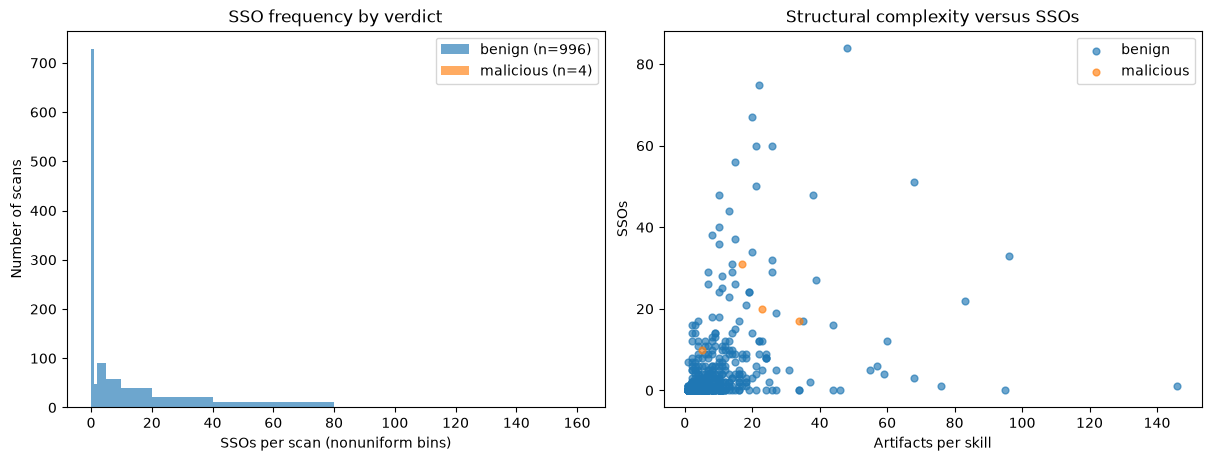

In [5]:
num_cols = ['finding_count','sso_count','artifact_count','operand_count','operand_resolution_count','runtime_sec']
summary_by_label = df.groupby('verdict')[num_cols].agg(['count','mean','median','max']).round(2)
display(summary_by_label)
high_benign = df[(df.verdict == 'benign') & df.has_sso].nlargest(HIGH_SSO_BENIGN_N,'sso_count').copy()
cols = ['package','sso_count','finding_count','artifact_count','pattern_matches','operand_resolution_count','retained_output']
display(high_benign[cols].head(20))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
bins = np.unique(np.r_[0, 1, 2, 5, 10, 20, 40, 80, 160, max(161, df.sso_count.max(skipna=True)+1)])
for label, subset in df.groupby('verdict'):
    axs[0].hist(subset.sso_count.dropna(), bins=bins, alpha=.65, label=f'{label} (n={len(subset)})')
axs[0].set(xlabel='SSOs per scan (nonuniform bins)', ylabel='Number of scans', title='SSO frequency by verdict')
axs[0].legend()
for label, subset in df.groupby('verdict'):
    axs[1].scatter(subset.artifact_count, subset.sso_count, label=f'{label}', alpha=.65, s=24)
axs[1].set(xlabel='Artifacts per skill', ylabel='SSOs', title='Structural complexity versus SSOs')
axs[1].legend()
if SAVE_OUTPUTS: fig.savefig(FIG_DIR / '03_ssos_and_complexity.png', dpi=180, bbox_inches='tight')
plt.show()

## 5. Recover exact evidence from saved case reports

Read `verdict.json`, `sso_findings.json`, `pattern_summary.json`, and `analysis_metadata.json` from the saved `cases/` folders where available. This step *does not run the scanner*. It builds joined evidence tables for the four flagged cases and makes missing reports visible rather than guessing.


In [6]:
def read_case_json(p, filename):
    if p is None: return None
    target = (p / filename).resolve()
    if not target.is_relative_to(RUN_DIR) or not target.is_file(): return None
    try:
        with target.open(encoding='utf-8') as f: return json.load(f)
    except (OSError, UnicodeError, ValueError) as exc:
        print(f'Could not parse {target}: {exc}')
        return None

cases = df if DETAIL_MODE == 'all' else pd.concat([df[df.is_malicious], high_benign]).drop_duplicates('entry_id')
metadata_rows, finding_rows, pattern_rows, case_coverage = [], [], [], []
for _, row in cases.iterrows():
    p = row['case_dir']
    verdict = read_case_json(p, 'verdict.json')
    findings = read_case_json(p, 'sso_findings.json')
    metadata = read_case_json(p, 'analysis_metadata.json')
    patterns = read_case_json(p, 'pattern_summary.json')
    has_v = isinstance(verdict, dict); has_f = isinstance(findings, list)
    has_m = isinstance(metadata, dict); has_p = isinstance(patterns, list)
    case_coverage.append({'entry_id':row.entry_id,'package':row.package,'verdict':row.verdict,
                          'has_verdict_file':has_v,'has_findings_file':has_f,'has_metadata_file':has_m,'has_patterns_file':has_p})
    if has_m:
        sg = metadata.get('semgrep') or {}
        metadata_rows.append({'entry_id':row.entry_id,'package':row.package,'verdict':row.verdict,
            'semgrep_status_metadata':sg.get('status'),
            'semgrep_match_count_metadata':sg.get('match_count'), 'semgrep_code_rule_count':sg.get('code_rule_count'),
            'candidate_collection_enabled':metadata.get('rule_candidate_collection'),
            'ruleset_digest':metadata.get('ruleset_digest')})
    if has_f:
        for f in findings:
            if not isinstance(f, dict): continue
            a, sp = f.get('attributes') or {}, f.get('span') or {}
            artifact = str(f.get('artifact_path') or '')
            finding_rows.append({'entry_id':row.entry_id, 'package':row.package, 'verdict':row.verdict,
                'finding_id':f.get('finding_id'), 'category':f.get('category'), 'subtype':f.get('subtype'),
                'producer':f.get('producer'), 'rule_id':a.get('rule_id'), 'artifact_path':artifact,
                'start_line':sp.get('start_line'), 'end_line':sp.get('end_line'),
                'from_markdown_fence':'.malskills_fences/' in artifact.replace('\\','/'),
                'matched_text':str(f.get('matched_text') or '')})
    # Prefer verdict explanations; fall back to pattern_summary.
    if has_v and isinstance(verdict.get('supporting_patterns'), list):
        detail_patterns = verdict.get('supporting_patterns') or []
    else:
        detail_patterns = patterns if has_p else []
    for pat in detail_patterns:
        if not isinstance(pat, dict): continue
        pattern_rows.append({'entry_id':row.entry_id, 'package':row.package, 'verdict':row.verdict,
            'pattern_name':pat.get('name'), 'severity':pat.get('severity'),
            'source':pat.get('source'), 'explanation':pat.get('explanation'),
            'rule_ids':pat.get('rule_ids') or [], 'finding_ids':pat.get('finding_ids') or [],
            'sso_ids':pat.get('sso_ids') or []})
metadata_df = pd.DataFrame(metadata_rows)
findings_df = pd.DataFrame(finding_rows)
patterns_df = pd.DataFrame(pattern_rows)
coverage_df = pd.DataFrame(case_coverage)
print(f'Read details for {len(cases):,} scan rows; {len(findings_df):,} individual SSO finding records.')
display(coverage_df[['has_verdict_file','has_findings_file','has_metadata_file','has_patterns_file']].sum().to_frame('cases present'))
if len(coverage_df) and not coverage_df.has_findings_file.all():
    print('NOTE: Fine-grained SSO category charts include only cases with sso_findings.json.')


Read details for 1,000 scan rows; 2,557 individual SSO finding records.


,cases present
has_verdict_file,1000
has_findings_file,1000
has_metadata_file,1000
has_patterns_file,1000


## 6. The decision boundary: SSOs versus malicious behavior patterns

This table directly addresses the **4/1,000 question** by showing which combinations of scanner observations led to which final verdicts. A large pool of skills with SSOs and no pattern match indicates that the composition rules are more selective than basic SSO detection.

Use the rule and proof tables below to determine **which conditions actually matched** in the flagged cases; do not assume every unflagged case lacks suspicious content.


In [7]:
decision = (
    df.groupby(['has_sso', 'has_pattern', 'verdict'], dropna=False)
      .agg(skills=('entry_id', 'count'),
           median_ssos=('sso_count', 'median'),
           median_artifacts=('artifact_count', 'median'))
      .reset_index().sort_values(['has_pattern', 'has_sso', 'verdict'])
)
decision['pct_all_scans'] = (100 * decision.skills / len(df)).round(2)
display(decision)

print('Skills with SSOs but no behavior-pattern match:',
      int((df.has_sso & ~df.has_pattern & ~df.has_error).sum()))
print('Skills with patterns but a non-malicious verdict:',
      int((df.has_pattern & ~df.is_malicious & ~df.has_error).sum()))
print('Scans with missing detailed case folders:', int((~df.case_available).sum()))

if not metadata_df.empty:
    print('Saved analysis metadata:')
    display(metadata_df[['semgrep_status_metadata','semgrep_match_count_metadata',
                         'semgrep_code_rule_count']].describe(include='all').T)

# Cross-check that counted pattern matches agree with the saved verdicts.
misalignment = df[(df.is_malicious & ~df.has_pattern) | (~df.is_malicious & df.has_pattern)]
if not misalignment.empty:
    print('Worth inspecting: verdict and pattern-count disagreement')
    display(misalignment[['package','status','verdict','sso_count','pattern_matches','retained_output']])


,has_sso,has_pattern,verdict,skills,median_ssos,median_artifacts,pct_all_scans
0,False,False,benign,729,0.0,1.0,72.9
1,True,False,benign,267,4.0,9.0,26.7
2,True,True,malicious,4,18.5,20.0,0.4


Skills with SSOs but no behavior-pattern match: 267
Skills with patterns but a non-malicious verdict: 0
Scans with missing detailed case folders: 0
Saved analysis metadata:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
semgrep_status_metadata,1000,1,ok,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
semgrep_match_count_metadata,1000.0,NaN,NaN,NaN,2.69,8.394186,0.0,0.0,0.0,1.0,84.0
semgrep_code_rule_count,1000.0,NaN,NaN,NaN,2665.0,0.0,2665.0,2665.0,2665.0,2665.0,2665.0


## 7. Which behavior patterns and formal rules actually fired?

Count **distinct affected skills**, not individual pattern mentions. Two patterns associated with one skill do not mean two separate malicious skills. Use the detailed proof records to recover the formal rule IDs responsible for each verdict.


,skills,cases
pattern_name,,
Malware_Delivery,4,4
Remote_Code_Execution,4,4


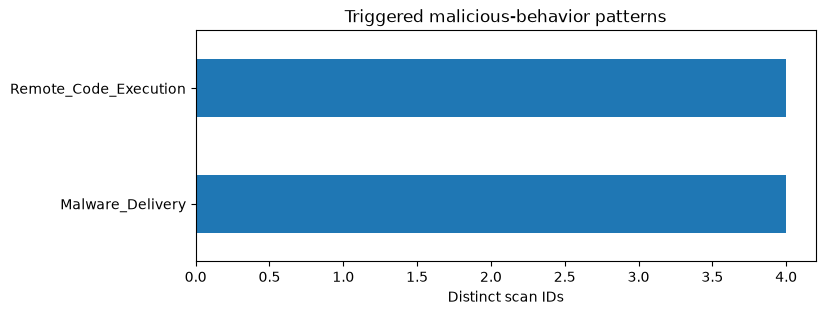

,,,unique_skills
pattern_name,rule_id,source,
Malware_Delivery,formal.graph.malware_delivery_memory,formal,4
Remote_Code_Execution,formal.graph.remote_code_execution,formal,4


In [8]:
pattern_expanded = []
for _, r in df.iterrows():
    for name in r['patterns']:
        pattern_expanded.append({'entry_id':r.entry_id, 'package':r.package, 'verdict':r.verdict, 'pattern_name':str(name)})
flat_patterns = pd.DataFrame(pattern_expanded, columns=['entry_id','package','verdict','pattern_name'])
if flat_patterns.empty:
    print('No behavior patterns listed in scan_results.jsonl.')
else:
    pattern_freq = flat_patterns.groupby('pattern_name').agg(skills=('entry_id','nunique'), cases=('package','nunique')).sort_values('skills',ascending=False)
    display(pattern_freq)
    fig, ax = plt.subplots(figsize=(8, max(3, .48*len(pattern_freq)+1)))
    pattern_freq.skills.sort_values().plot.barh(ax=ax)
    ax.set(title='Triggered malicious-behavior patterns', xlabel='Distinct scan IDs', ylabel='')
    if SAVE_OUTPUTS: fig.savefig(FIG_DIR / '04_triggered_behavior_patterns.png', dpi=180, bbox_inches='tight')
    plt.show()
if not patterns_df.empty:
    detailed_rules=[]
    for _, p in patterns_df.iterrows():
        for rule in p.rule_ids:
            detailed_rules.append({'package':p.package,'pattern_name':p.pattern_name,'rule_id':rule,'source':p.source})
    if detailed_rules:
        display(pd.DataFrame(detailed_rules).groupby(['pattern_name','rule_id','source']).package.nunique().rename('unique_skills').to_frame())

### Pattern severity and reasoning provenance

Summarize how the **matched behavior patterns** are classified by the scanner, as distinct from individual SSOs. The provenance and rule identifiers make the counts reproducible.


,severity,source,skills,matches
0,high,formal,4,8


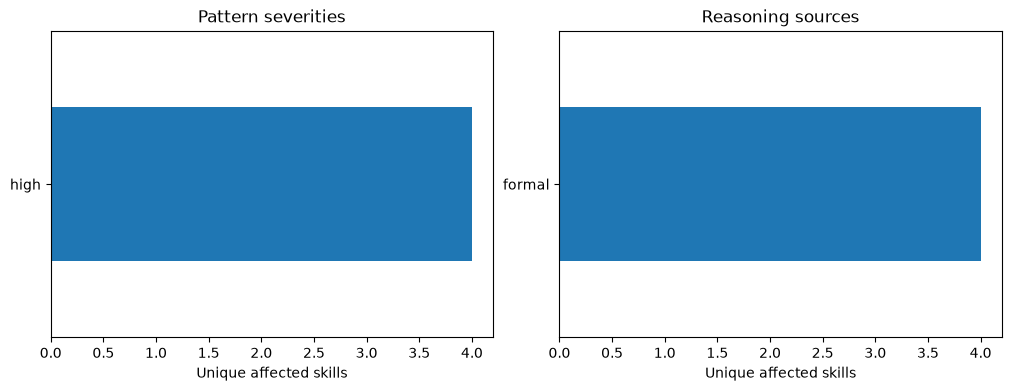

In [9]:
if patterns_df.empty:
    print('No per-pattern severity/provenance details were retained.')
else:
    sev = patterns_df.groupby(['severity','source'],dropna=False).agg(skills=('entry_id','nunique'),matches=('pattern_name','size')).reset_index()
    display(sev)
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
    by_sev = patterns_df.groupby('severity',dropna=False).entry_id.nunique().sort_values()
    by_src = patterns_df.groupby('source',dropna=False).entry_id.nunique().sort_values()
    by_sev.plot.barh(ax=axs[0]); axs[0].set(title='Pattern severities',xlabel='Unique affected skills',ylabel='')
    by_src.plot.barh(ax=axs[1]); axs[1].set(title='Reasoning sources',xlabel='Unique affected skills',ylabel='')
    if SAVE_OUTPUTS: fig.savefig(FIG_DIR/'06_pattern_severity_and_provenance.png',dpi=180,bbox_inches='tight')
    plt.show()

## 8. Four malicious verdicts: rule-to-evidence traces

Trace each flagged skill from its **matched behavior pattern → formal rule IDs → finding IDs → source files and line numbers → matched text**. Where present, show the recorded command text as inert output. This section explains the scanner's reported triggers, without introducing external classifications or reviewer labels.


In [10]:
flagged = df[df.is_malicious].sort_values('package').copy()
display(flagged[['package','sso_count','finding_count','artifact_count','patterns','retained_output']])

joined = []
if not patterns_df.empty and not findings_df.empty:
    indexed_findings = {(f.entry_id, str(f.finding_id)): f for _, f in findings_df.iterrows()}
    for _, pat in patterns_df[patterns_df.verdict == 'malicious'].iterrows():
        for fid in pat.finding_ids:
            f = indexed_findings.get((pat.entry_id, str(fid)))
            joined.append({'package':pat.package, 'pattern':pat.pattern_name,
                'reasoning_source':pat.source, 'formal_rule_ids':'; '.join(map(str,pat.rule_ids)),
                'finding_id':fid, 'sso_category':None if f is None else f.category,
                'artifact':None if f is None else f.artifact_path,
                'line':None if f is None else f.start_line,
                'markdown_fence':None if f is None else f.from_markdown_fence,
                'evidence':None if f is None else f.matched_text,
                'explanation':pat.explanation})
evidence_df = pd.DataFrame(joined)
if evidence_df.empty:
    print('Detailed proof-to-source joins unavailable; copy the full cases/ tree for the flagged skills.')
else:
    key = ['package','artifact','line','evidence']
    unique_evidence = evidence_df.drop_duplicates(subset=key).copy()
    print('Distinct source-grounded evidence locations:', len(unique_evidence))
    display(unique_evidence[['package','artifact','line','sso_category','markdown_fence']])
    if SHOW_MATCHED_TEXT:
        # text is displayed but never executed; keep the rendering inside a code block
        for package, part in unique_evidence.groupby('package',sort=True):
            display(Markdown(f'### {package}'))
            for _, r in part.head(12).iterrows():
                snippet = str(r.evidence).replace('`', 'ˋ')[:500]
                print(f'{r.artifact} (line {r.line})  [{r.sso_category}]')
                print('  ', snippet)
    print('Proof rules:')
    display(evidence_df[['package','pattern','formal_rule_ids','reasoning_source']].drop_duplicates())
# Compact, reproducible case-study summary from actual proof records.
if not evidence_df.empty:
    evidence_summary = (evidence_df.groupby('package', dropna=False)
        .agg(patterns=('pattern', lambda x: '; '.join(sorted({str(v) for v in x if pd.notna(v)}))),
             rule_ids=('formal_rule_ids', lambda x: '; '.join(sorted({str(v) for v in x if pd.notna(v)}))),
             evidence_locations=('artifact', 'nunique'))
        .reset_index())
    evidence_summary['remote_script_pipe'] = evidence_summary['package'].map(
        evidence_df.assign(remote_script_pipe=evidence_df.evidence.fillna('').str.contains(
            r'(?:curl|wget)\b[^\n]*\|\s*(?:sh|bash)\b', flags=re.I, regex=True))
            .groupby('package').remote_script_pipe.any())
    display(evidence_summary)
    print('CAUTION: a remote-script-to-shell pattern is risky but does not alone establish malicious intent.')


,package,sso_count,finding_count,artifact_count,patterns,retained_output
49,skill_0050,17,17,34,"[Malware_Delivery, Remote_Code_Execution]",cases/exported_skills_skill_0050__7c20270d59
451,skill_0452,20,20,23,"[Malware_Delivery, Remote_Code_Execution]",cases/exported_skills_skill_0452__3c07e78b7e
637,skill_0636,31,31,17,"[Malware_Delivery, Remote_Code_Execution]",cases/exported_skills_skill_0636__55cfd4c1c9
966,skill_0964,10,10,5,"[Malware_Delivery, Remote_Code_Execution]",cases/exported_skills_skill_0964__8472714081


Distinct source-grounded evidence locations: 4


,package,artifact,line,sso_category,markdown_fence
0,skill_0050,.malskills_fences/SKILL__fence_105.sh,1,network_access,True
4,skill_0452,.malskills_fences/SKILL__fence_0.sh,2,network_access,True
8,skill_0636,data/.malskills_fences/install__fence_2.sh,1,network_access,True
12,skill_0964,.malskills_fences/SKILL__fence_0.sh,1,network_access,True


### skill_0050

.malskills_fences/SKILL__fence_105.sh (line 1)  [network_access]
   curl https://mise.run | sh


### skill_0452

... (4 outputs left out)

.malskills_fences/SKILL__fence_0.sh (line 1)  [network_access]
   curl -sSL https://canifi.com/skills/discord-nitro/install.sh | bash
Proof rules:


,package,pattern,formal_rule_ids,reasoning_source
0,skill_0050,Malware_Delivery,formal.graph.malware_delivery_memory,formal
2,skill_0050,Remote_Code_Execution,formal.graph.remote_code_execution,formal
4,skill_0452,Malware_Delivery,formal.graph.malware_delivery_memory,formal
6,skill_0452,Remote_Code_Execution,formal.graph.remote_code_execution,formal
8,skill_0636,Malware_Delivery,formal.graph.malware_delivery_memory,formal
10,skill_0636,Remote_Code_Execution,formal.graph.remote_code_execution,formal
12,skill_0964,Malware_Delivery,formal.graph.malware_delivery_memory,formal
14,skill_0964,Remote_Code_Execution,formal.graph.remote_code_execution,formal


,package,patterns,rule_ids,evidence_locations,remote_script_pipe
0,skill_0050,Malware_Delivery; Remote_Code_Execution,formal.graph.malware_delivery_memory; formal.g...,1,True
1,skill_0452,Malware_Delivery; Remote_Code_Execution,formal.graph.malware_delivery_memory; formal.g...,1,True
2,skill_0636,Malware_Delivery; Remote_Code_Execution,formal.graph.malware_delivery_memory; formal.g...,1,True
3,skill_0964,Malware_Delivery; Remote_Code_Execution,formal.graph.malware_delivery_memory; formal.g...,1,True


CAUTION: a remote-script-to-shell pattern is risky but does not alone establish malicious intent.


## 9. MalSkills SSO categories

Use the **original MalSkills SSO category labels**. Report both **finding instances** and **distinct skills with each category**. Show category incidence for each verdict group as an additional comparison.


,findings,skills,pct_scanned
category,,,
file_operation,968,178,17.8
payload_execution,336,88,8.8
sensitive_data_access,402,79,7.9
network_access,496,74,7.4
software_installation,238,62,6.2
system_configuration,58,29,2.9
cryptography,26,18,1.8
process_operation,33,12,1.2


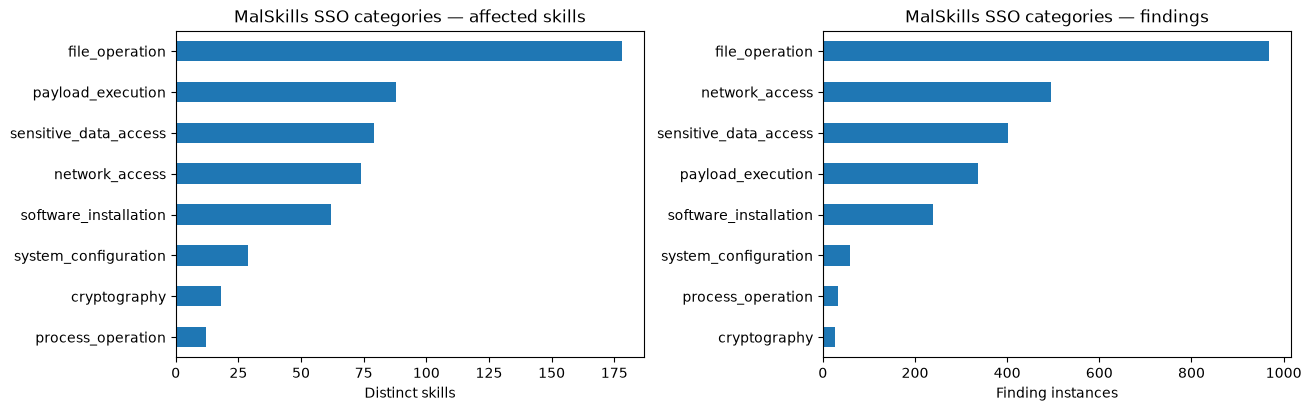

findings  skills
verdict   from_markdown_fence                  
benign    False                    1135     166
          True                     1344     200
malicious False                      17       4
          True                       61       4

verdict,benign (% of verdict group),malicious (% of verdict group)
MalSkills SSO category,,
cryptography,1.8,0.0
file_operation,17.6,75.0
network_access,7.0,100.0
payload_execution,8.4,100.0
process_operation,1.2,0.0
sensitive_data_access,7.8,25.0
software_installation,5.8,100.0
system_configuration,2.6,75.0


In [11]:
if findings_df.empty:
    cats = pd.DataFrame(columns=['findings', 'skills', 'pct_scanned'])
    incidence_pct = pd.DataFrame()
    print('SSO category records unavailable: sso_findings.json files were not found.')
else:
    cats = (findings_df.groupby('category', dropna=False)
            .agg(findings=('finding_id','count'), skills=('entry_id','nunique'))
            .sort_values(['skills','findings'], ascending=False))
    cats['pct_scanned'] = (100 * cats.skills / n).round(1)
    display(cats)

    fig, axs = plt.subplots(1, 2,
                            figsize=(13, max(4, .4 * len(cats.head(12)))),
                            constrained_layout=True)
    cats.head(12).skills.sort_values().plot.barh(ax=axs[0])
    axs[0].set(title='MalSkills SSO categories — affected skills', xlabel='Distinct skills', ylabel='')
    cats.head(12).findings.sort_values().plot.barh(ax=axs[1])
    axs[1].set(title='MalSkills SSO categories — findings', xlabel='Finding instances', ylabel='')
    if SAVE_OUTPUTS:
        fig.savefig(FIG_DIR / '05_malskills_sso_categories.png', dpi=180, bbox_inches='tight')
    plt.show()

    location = findings_df.groupby(['verdict','from_markdown_fence']).agg(
        findings=('finding_id','count'), skills=('entry_id','nunique'))
    display(location)

    top_categories = cats.head(12).index.astype(str).tolist()
    incidences = (findings_df[findings_df.category.astype(str).isin(top_categories)]
                  [['entry_id','verdict','category']].drop_duplicates())
    incidence_counts = incidences.groupby(['category','verdict']).entry_id.nunique().unstack(fill_value=0)
    denominators = df.groupby('verdict').entry_id.count()
    incidence_pct = (incidence_counts.div(denominators, axis=1) * 100).round(1)
    display(incidence_pct.rename_axis('MalSkills SSO category').add_suffix(' (% of verdict group)'))


## 10. High-SSO skills without malicious verdicts

Identify skills with many recorded SSOs but **no matched malicious behavior pattern**. Compare their SSO volume and categories with the four flagged skills to show that high operation counts alone do not determine the scanner verdict.


In [12]:
print('Benign + SSO > 0 + no pattern:', int(((df.verdict=='benign') & df.has_sso & ~df.has_pattern).sum()))
benign_outliers = df[(df.verdict=='benign') & df.has_sso & ~df.has_pattern].nlargest(15,'sso_count')
display(benign_outliers[['package','sso_count','finding_count','artifact_count','pattern_matches','operand_resolution_count']])
if not findings_df.empty and len(benign_outliers):
    outlier_cats = findings_df[findings_df.entry_id.isin(benign_outliers.entry_id)].groupby(['package','category']).size().rename('findings').reset_index()
    display(outlier_cats.sort_values(['package','findings'],ascending=[True,False]).head(35))
print('Counterexample principle: isolated SSOs can accumulate without matching a malicious-behavior rule.')
if 'skill_0451' in df.package.values:
    display(df.loc[df.package=='skill_0451', ['package','sso_count','pattern_matches','verdict']])


Benign + SSO > 0 + no pattern: 267


,package,sso_count,finding_count,artifact_count,pattern_matches,operand_resolution_count
193,skill_0193,84,84,48,0,0
469,skill_0467,75,75,22,0,0
391,skill_0391,67,67,20,0,0
736,skill_0736,60,60,26,0,0
878,skill_0874,60,60,21,0,0
454,skill_0451,56,56,15,0,0
604,skill_0602,51,51,68,0,0
91,skill_0089,50,50,21,0,0
484,skill_0480,48,48,10,0,0
727,skill_0725,48,48,38,0,0


,package,category,findings
1,skill_0089,sensitive_data_access,45
0,skill_0089,file_operation,5
4,skill_0121,network_access,26
3,skill_0121,file_operation,10
2,skill_0121,cryptography,1
5,skill_0121,payload_execution,1
6,skill_0193,network_access,79
7,skill_0193,payload_execution,3
8,skill_0193,sensitive_data_access,1
9,skill_0193,system_configuration,1


Counterexample principle: isolated SSOs can accumulate without matching a malicious-behavior rule.


,package,sso_count,pattern_matches,verdict
454,skill_0451,56,0,benign


## 11. Why were only four skills flagged?

Summarize what the saved MalSkills outputs establish: total malicious verdicts, skills containing SSOs, skills with matched patterns, and formal rule IDs linked to the four flagged cases. This section describes the **scanner's decision pattern** using observed data only.


In [13]:
n_ssos = int(df.has_sso.sum())
n_pattern = int(df.has_pattern.sum())
n_flag = int(df.is_malicious.sum())
print(f'MALSKILLS RESULTS: {n_flag:,} malicious verdicts / {n:,} scanned = {n_flag/n:.2%}')
print(f'Scans with one or more SSOs: {n_ssos:,} / {n:,} ({n_ssos/n:.1%})')
print(f'Scans with matched behavior patterns: {n_pattern:,} / {n:,} ({n_pattern/n:.1%})')
print(f'SSOs but no behavior match: {int((df.has_sso & ~df.has_pattern).sum()):,}')
print(f'No SSO detected: {int((~df.has_sso).sum()):,}')
print(f'Non-OK/error scans: {int(df.has_error.sum()):,}')

if not patterns_df.empty:
    rule_set = set()
    for rule_list in patterns_df.rule_ids:
        if isinstance(rule_list, list):
            rule_set.update(str(r) for r in rule_list)
    print('Rule IDs appearing in saved matched-pattern evidence:', ', '.join(sorted(rule_set)) or 'none supplied')

if not evidence_df.empty:
    proof = evidence_df.copy()
    proof['remote_shell_pipeline'] = proof.evidence.fillna('').str.contains(
        r'(?:curl|wget)\b[^\n]*\|\s*(?:sh|bash)\b', case=False, regex=True)
    pipeline_packages = sorted(proof.loc[proof.remote_shell_pipeline, 'package'].dropna().unique())
    print('Flagged packages with remote-script-to-shell proof evidence:', ', '.join(pipeline_packages) or 'none found')

print("""
SCAN-RESULT SUMMARY
Malicious verdicts reflect matched MalSkills behavior patterns, not SSO counts alone.
Use the tables above to compare scans with SSOs, scans with matching patterns, and the
rule and evidence traces of the flagged cases. The observed percentage is a scanner
verdict rate for these 1,000 results.
""")


MALSKILLS RESULTS: 4 malicious verdicts / 1,000 scanned = 0.40%
Scans with one or more SSOs: 271 / 1,000 (27.1%)
Scans with matched behavior patterns: 4 / 1,000 (0.4%)
SSOs but no behavior match: 267
No SSO detected: 729
Non-OK/error scans: 0
Rule IDs appearing in saved matched-pattern evidence: formal.graph.malware_delivery_memory, formal.graph.remote_code_execution
Flagged packages with remote-script-to-shell proof evidence: skill_0050, skill_0452, skill_0636, skill_0964

SCAN-RESULT SUMMARY
Malicious verdicts reflect matched MalSkills behavior patterns, not SSO counts alone.
Use the tables above to compare scans with SSOs, scans with matching patterns, and the
rule and evidence traces of the flagged cases. The observed percentage is a scanner
verdict rate for these 1,000 results.



## 12. Export figures, CSVs, and a MalSkills results summary

Save analysis tables, per-rule evidence, MalSkills SSO categories, and charts to `results/malskills_analysis/package_test_2/`. The original scan results are read-only. Matched source excerpts are excluded from CSV exports by default.


In [14]:
if SAVE_OUTPUTS:
    export_frames = {
        'scan_summary.csv': df.drop(columns=['case_dir','patterns','scan_path'], errors='ignore').copy(),
        'verdict_distribution.csv': labels.reset_index(),
        'detection_funnel.csv': funnel,
        'outcome_groups.csv': reason_table.reset_index(),
        'verdict_rule_decision.csv': decision,
        'high_sso_benign.csv': high_benign.drop(columns=['case_dir','patterns','scan_path'], errors='ignore'),
        'per_case_coverage.csv': coverage_df,
    }
    if not metadata_df.empty:
        export_frames['analysis_metadata.csv'] = metadata_df
    if not cats.empty:
        export_frames['sso_category_summary.csv'] = cats.reset_index()
    if not incidence_pct.empty:
        export_frames['sso_category_incidence_pct.csv'] = incidence_pct.reset_index()
    if not flat_patterns.empty:
        export_frames['pattern_occurrences.csv'] = flat_patterns
    if not patterns_df.empty:
        proof_export = patterns_df.copy()
        for col in ['rule_ids','finding_ids','sso_ids']:
            proof_export[col] = proof_export[col].apply(
                lambda v: '; '.join(map(str,v)) if isinstance(v,list) else str(v))
        export_frames['pattern_proofs.csv'] = proof_export
    if not findings_df.empty:
        export_frames['sso_findings.csv'] = (findings_df if EXPORT_MATCHED_TEXT
                                                else findings_df.drop(columns=['matched_text']))
    if not evidence_df.empty:
        export_frames['flagged_evidence.csv'] = (evidence_df if EXPORT_MATCHED_TEXT
                                                 else evidence_df.drop(columns=['evidence']))
        export_frames['flagged_case_study.csv'] = evidence_summary
    for filename, frame in export_frames.items():
        frame.to_csv(TABLE_DIR / filename, index=False)

    lines = [
        '# MalSkills — 1,000-skill analysis (`package_test_2`)',
        '', '## Corpus and verdicts',
        f'- Scan rows: **{n:,}**',
        f'- Distinct entry IDs: **{df.entry_id.nunique():,}**',
        f'- Malicious verdicts: **{n_flag:,}/{n:,} ({n_flag/n:.2%})**',
        f'- Benign verdicts: **{int(df.verdict.eq("benign").sum()):,}**',
        f'- Failed/non-OK rows: **{int(df.has_error.sum()):,}**',
        f'- Skills with >=1 SSO: **{n_ssos:,}**',
        f'- Skills with matched behavior patterns: **{n_pattern:,}**',
        f'- Skills with SSOs but no matched pattern: **{int((df.has_sso & ~df.has_pattern).sum()):,}**',
        f'- Preserved case directories: **{int(df.case_available.sum()):,}**',
        '', '## Four flagged cases',
    ]
    for _, r in flagged.iterrows():
        patt = ', '.join(map(str, r.patterns)) or '(not listed in summary)'
        lines.append(f'- `{r.package}`: SSOs={int(r.sso_count)}, matched patterns={patt}')
    lines += [
        '', '## Observed MalSkills detection pattern',
        'Malicious verdicts correspond to matched MalSkills behavior patterns rather than merely high SSO counts.',
        'See pattern_proofs.csv and flagged_case_study.csv for the rules and source-linked evidence.',
        '', f'Input directory: `{RUN_DIR}`',
    ]
    (OUT_DIR / 'START_HERE.md').write_text('\n'.join(lines) + '\n', encoding='utf-8')
    print('Saved:', OUT_DIR / 'START_HERE.md')
    print('Tables:', len(export_frames), '| Figures:', len(list(FIG_DIR.glob('*.png'))))
else:
    print('Set SAVE_OUTPUTS=True to export charts, CSVs, and a research summary.')


Saved: /Users/samantharies/PycharmProjects/MSR2027/SkillGuard/results/malskills_analysis/package_test_2/START_HERE.md
Tables: 15 | Figures: 7
